# Titanic - Modelagem

Treinamos e comparamos modelos de machine learning usando as features de `src/features.py`. A meta é passar a baseline "mulher sobrevive" (**78,7%** no treino, **0,76555** no Kaggle).

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from src.features import criar_features, COLUNAS_NUMERICAS, COLUNAS_CATEGORICAS, COLUNAS_BINARIAS

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

X = criar_features(train)
y = train['Survived']
X_teste = criar_features(test)

## 1. Pré-processamento dentro de um Pipeline

O `ColumnTransformer` aplica um tratamento diferente para cada tipo de coluna:

- **Numéricas:** preenche faltantes com a mediana e coloca tudo na mesma escala (`StandardScaler`).
- **Categóricas:** preenche com o valor mais comum e transforma cada categoria numa coluna 0/1 (*one-hot encoding*).
- **Binárias:** já são 0/1, passam direto.

Colocar isso num `Pipeline` junto com o modelo garante que medianas e categorias sejam aprendidas **só com os dados de treino de cada rodada**, sem vazamento.

In [2]:
preprocessamento = ColumnTransformer([
    ('num', Pipeline([
        ('preencher', SimpleImputer(strategy='median')),
        ('escala', StandardScaler()),
    ]), COLUNAS_NUMERICAS),
    ('cat', Pipeline([
        ('preencher', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]), COLUNAS_CATEGORICAS),
    ('bin', 'passthrough', COLUNAS_BINARIAS),
])

def montar(modelo):
    return Pipeline([('pre', preprocessamento), ('modelo', modelo)])

## 2. Validação cruzada

Se avaliássemos o modelo nos mesmos dados em que ele treinou, ele pareceria melhor do que é. Na **validação cruzada** com 5 partes, o treino é dividido em 5 pedaços: o modelo treina em 4 e é avaliado no que sobrou, 5 vezes. A nota final é a média.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    'Regressão Logística': LogisticRegression(max_iter=1000),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

resultados = []
for nome, modelo in modelos.items():
    notas = cross_val_score(montar(modelo), X, y, cv=cv)
    resultados.append({'modelo': nome, 'acurácia média': notas.mean(), 'desvio': notas.std()})

resultados = pd.DataFrame(resultados).sort_values('acurácia média', ascending=False)
resultados.round(3)

,modelo,acurácia média,desvio
3,Gradient Boosting,0.839,0.021
0,Regressão Logística,0.836,0.012
2,Random Forest,0.818,0.012
1,Árvore de Decisão,0.815,0.023


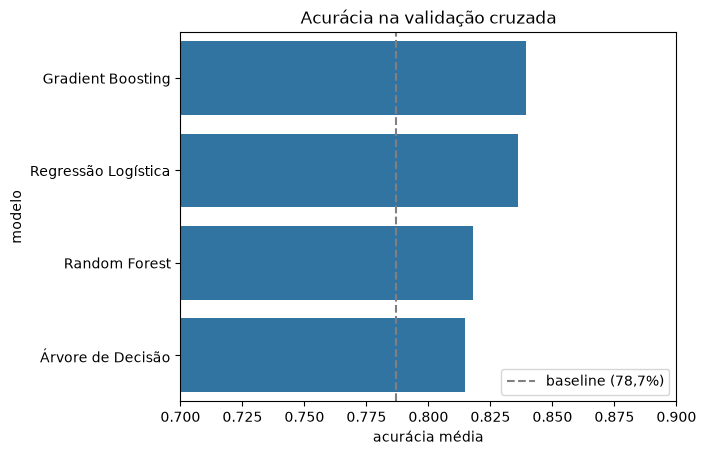

In [4]:
sns.barplot(data=resultados, y='modelo', x='acurácia média')
plt.axvline(0.787, color='gray', linestyle='--', label='baseline (78,7%)')
plt.xlim(0.7, 0.9)
plt.legend()
plt.title('Acurácia na validação cruzada')
plt.savefig('../reports/figures/comparacao_modelos.png', dpi=150, bbox_inches='tight')
plt.show()

Todos os modelos passam a baseline. **Gradient Boosting** e **Regressão Logística** ficam na frente, com cerca de 84%. A Árvore de Decisão sozinha é a mais fraca e a mais instável (maior desvio).

## 3. Ajuste de hiperparâmetros

Cada modelo tem configurações (*hiperparâmetros*) que não são aprendidas dos dados, como o número de árvores ou a profundidade máxima. O `GridSearchCV` testa todas as combinações de uma lista, cada uma com validação cruzada, e fica com a melhor.

In [5]:
busca_rf = GridSearchCV(
    montar(RandomForestClassifier(random_state=42)),
    {
        'modelo__n_estimators': [200, 500],
        'modelo__max_depth': [4, 6, 8, None],
        'modelo__min_samples_leaf': [1, 3, 5],
    },
    cv=cv,
)
busca_rf.fit(X, y)
busca_rf.best_params_, round(busca_rf.best_score_, 3)

({'modelo__max_depth': None,
  'modelo__min_samples_leaf': 3,
  'modelo__n_estimators': 200},
 np.float64(0.839))

In [6]:
busca_gb = GridSearchCV(
    montar(GradientBoostingClassifier(random_state=42)),
    {
        'modelo__n_estimators': [100, 300],
        'modelo__max_depth': [2, 3],
        'modelo__learning_rate': [0.05, 0.1],
    },
    cv=cv,
)
busca_gb.fit(X, y)
busca_gb.best_params_, round(busca_gb.best_score_, 3)

({'modelo__learning_rate': 0.05,
  'modelo__max_depth': 3,
  'modelo__n_estimators': 300},
 np.float64(0.845))

O ajuste melhorou os dois modelos: o Random Forest subiu de cerca de 81,8% para 84%, e o Gradient Boosting de 84% para 84,5%.

## 4. Onde o modelo erra: matriz de confusão

`cross_val_predict` gera, para cada passageiro do treino, a previsão feita por um modelo que **não** o viu no treino.

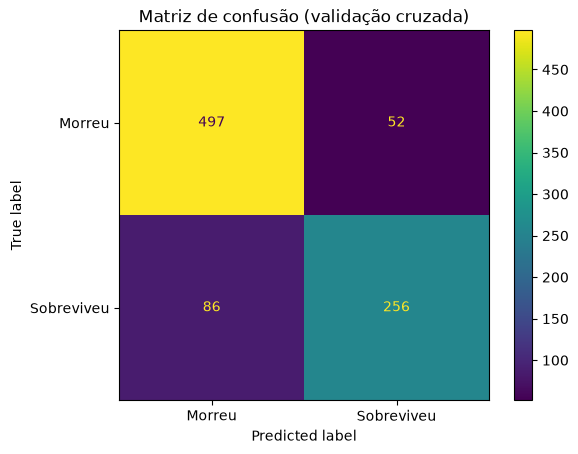

In [7]:
melhor = busca_gb.best_estimator_

previsoes = cross_val_predict(melhor, X, y, cv=cv)
ConfusionMatrixDisplay.from_predictions(y, previsoes, display_labels=['Morreu', 'Sobreviveu'])
plt.title('Matriz de confusão (validação cruzada)')
plt.show()

A diagonal mostra os acertos. O erro mais comum é prever que alguém morreu quando na verdade sobreviveu: o modelo é "pessimista", como já era a baseline com os homens.

## 5. Quais features mais pesam?

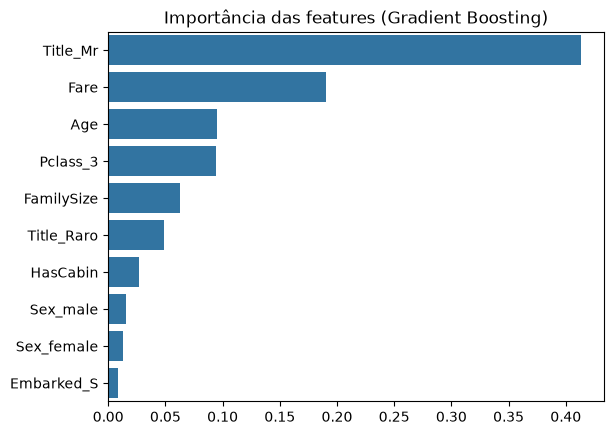

In [8]:
modelo_gb = melhor.named_steps['modelo']
nomes = melhor.named_steps['pre'].get_feature_names_out()

importancia = (
    pd.Series(modelo_gb.feature_importances_, index=nomes)
    .sort_values(ascending=False)
    .head(10)
)
importancia.index = importancia.index.str.split('__').str[1]

sns.barplot(x=importancia.values, y=importancia.index)
plt.ylabel('')
plt.title('Importância das features (Gradient Boosting)')
plt.savefig('../reports/figures/importancia_features.png', dpi=150, bbox_inches='tight')
plt.show()

O título `Mr` (homem adulto) é de longe a feature mais importante: ele junta sexo e idade numa coisa só. Depois vêm tarifa, idade, estar na 3ª classe e tamanho da família. A feature `Title`, criada no notebook anterior, valeu a pena.

## 6. Submissões

Geramos uma submissão para cada candidato. Além dos dois modelos ajustados, entram duas versões **mais simples**: a Regressão Logística e um Random Forest com árvores rasas (`max_depth=5`), menos capaz de decorar detalhes do treino.

In [9]:
finais = {
    'random_forest': busca_rf.best_estimator_,
    'gradient_boosting': busca_gb.best_estimator_,
    'regressao_logistica': montar(LogisticRegression(max_iter=1000)),
    'random_forest_raso': montar(RandomForestClassifier(
        n_estimators=500, max_depth=5, min_samples_leaf=3, random_state=42)),
}

for nome, modelo in finais.items():
    modelo.fit(X, y)  # treina com todo o treino
    submissao = pd.DataFrame({
        'PassengerId': test['PassengerId'],
        'Survived': modelo.predict(X_teste),
    })
    submissao.to_csv(f'../submissions/{nome}.csv', index=False)
    print(nome, submissao.shape)

random_forest (418, 2)


gradient_boosting (418, 2)
regressao_logistica (418, 2)


random_forest_raso (418, 2)


## 7. Resultados no Kaggle

| Modelo | Validação cruzada | Kaggle |
| --- | --- | --- |
| Baseline "mulher sobrevive" | 78,7% | 0,76555 |
| Gradient Boosting ajustado | 84,5% | 0,76315 |
| Regressão Logística | 83,6% | 0,76794 |
| Random Forest ajustado | 83,9% | 0,77033 |
| **Random Forest raso** (`max_depth=5`) | 83,2% | **0,77751** |

**Lição principal:** a melhor nota na validação cruzada (Gradient Boosting, 84,5%) teve a **pior** nota no Kaggle, abaixo até da baseline. Ele aprendeu detalhes do treino que não valem para passageiros novos (*overfitting*). O Random Forest raso tinha a menor nota na validação, mas generalizou melhor.

A diferença de 6 a 8 pontos entre validação e Kaggle mostra que, com só 891 passageiros, a validação cruzada é otimista. Diferenças de 1 ponto entre modelos estão dentro do ruído. Por isso paramos aqui: continuar ajustando o modelo de olho na nota do Kaggle seria overfitting no próprio ranking.